# Dinámica de un cuerpo rígido asimétrico


##### Caterine Bedoya Bedoya




Consideramos un sistema formado por un cuerpo rigido asimétrico  libre de torques externos,el cual está sometido a un movimiento de rotación pura. El problema prinicpal radica en describir matematicamente el comportamiento de las componentes de la velocidad angular de este objeto como funciones del tiempo.Para lograr esto, se disponen de las ecuaciones de Euler encargadas de predecir la evolución de la velocidad angular de solidos rigidos, asi como las leyes de conservación de la Energía y  conservación del Momento angular, las cuales permiten reducir  las variables dinámicas a un solo grado de libertad.
Para mayor conveniencia,  y siguiendo el tratamiento que presenta Landau en su libro de *Mecánica*, se considera que el giro del cuerpo tiene lugar a lo largo de sus ejes principales de inercia y que los respectivos momentos principales de inercia, toman valores en orden ascendente.

Se presenta las gráficas de las soluciones del problema , revelando cualitativamente la inestabilidad del movimiento del objeto asimétrico entorno al su eje principal intermedio.

### Soluciones numéricas a las ecuaciones de Euler.

A continución se presenta un código que resuelve numéricamente el sistema acoplado de ecuaciones de Euler para las componentes de velocidad angular del cuerpo rígido asimétrico. Se tomaron las condiciones iniciales con cierta arbitrariedad, pero con la condición de que el movimiento de rotación de partida del objeto ocurra principalmente entorno al eje asociado al momento de inercia principal de valor intermedio,de tal manera que las gráficas resultantes permitan visualizar el cambio repentino que sufre la componente  velocidad angular entorno a este eje.

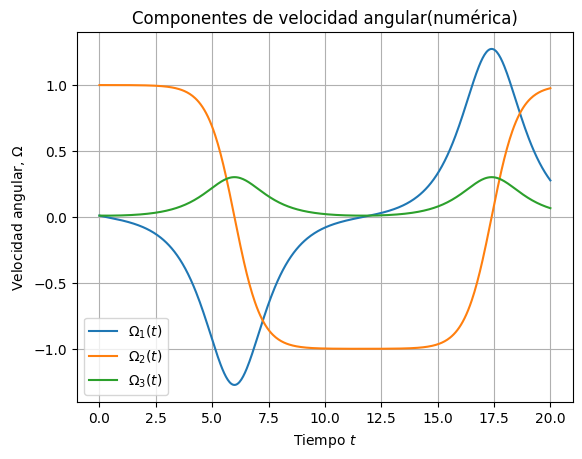

In [7]:
import numpy as np
from scipy import special
from scipy.integrate import odeint
import matplotlib.pyplot as plt

I1 = 0.7
I2 = 1.5
I3 = 4


t = np.linspace(0,20,500)

Ω1_0= 0.01
Ω2_0= 1.
Ω3_0= 0.01
W_0=(Ω1_0,Ω2_0,Ω3_0)


def dWdt(t,W):
  Ω1n, Ω2n, Ω3n = W
  return [((I2-I3)/I1)*Ω2n*Ω3n,
          ((I3-I1)/I2)*Ω3n*Ω1n,
          ((I1-I2)/I3)*Ω1n*Ω2n,
          ]

solucion = odeint(dWdt, y0 = W_0, t=t, tfirst=True)

Ω1n=solucion.T[0]
Ω2n=solucion.T[1]
Ω3n=solucion.T[2]


plt.title('Componentes de velocidad angular(numérica)')
plt.plot(t,Ω1n,label='$Ω_1(t)$')
plt.plot(t,Ω2n,label='$Ω_2(t)$')
plt.plot(t,Ω3n,label='$Ω_3(t)$')
plt.xlabel('Tiempo $t$')
plt.ylabel('Velocidad angular, $Ω$')
plt.legend()
plt.grid()
plt.show()



In [15]:
# Igualemente, se obtiene la Energia total y el Momento angular para esta solución numérica
# Debido a que tanto la energía como el momento angular se conservan, extraemos el valor maximo de los arreglos generados para tales cantidades

En= np.max(( I1* (Ω1n)**2 + I2* (Ω2n)**2 + I3* (Ω3n)**2 )/2) # Valor de la energía
Mn =np.max(((I1*Ω1n)**2 +(I2*Ω2n)**2 +(I3*Ω3n)**2)**0.5) # Valor del módulo del momento angular

En

0.750235031812458

In [17]:

k=np.sqrt(((I2-I1)*(2*En*I3 - Mn**2))/((I3-I2)*(Mn**2 -2*En*I1)))  # Modulo de la funcion eliptica de Jacobi

tau = t*np.sqrt((I3-I2)*(Mn**2-2*En*I1)/I1*I2*I3)

# Calcular las funciones elípticas de Jacobi
sn, cn, dn, ph = special.ellipj(tau, k)

print('módulo elíptico: κ = ',k)



módulo elíptico: κ =  0.999481235447029


In [19]:
# Arreglos con las componentes de la velocidad angular en funcion del tiempo:

ω1= np.sqrt((2*En*I3 - Mn**2)/(I1*(I3-I1)))*cn
ω2= np.sqrt((2*En*I3 - Mn**2)/(I2*(I3-I2)))*sn
ω3= np.sqrt((Mn**2 - 2*En*I1 )/(I3*(I3-I1)))*dn

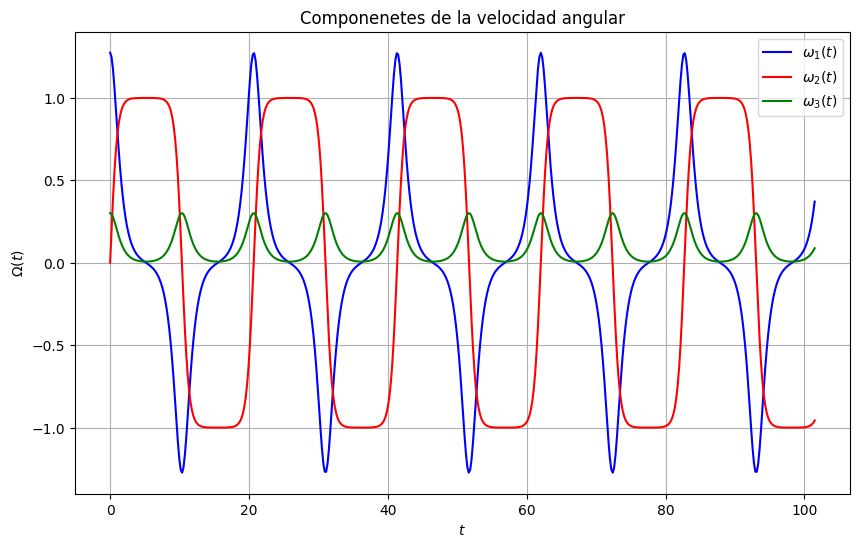

In [23]:
# Graficar de las soluciones analíticas para las componentes de la velocidad angular proporcionadas por la solucion numerica.

plt.figure(figsize=(10, 6))
plt.plot(tau, ω1, label='$ω_1 (t)$',color='blue')
plt.plot(tau, ω2, label='$ω_2 (t)$',color='red')
plt.plot(tau, ω3, label='$ω_3 (t)$',color='green')
plt.xlabel('$t$')
plt.title('Componenetes de la velocidad angular')
plt.ylabel('$Ω(t)$')
plt.legend()
plt.grid()
plt.show()

### Soluciones Analiticas mediante las funciones  elípticas de Jacobi.

Se considera el movimiento libre de una peonza asimétrica, cuyos tres momentos principales de inercia son diferentes. Para fijar ideas, suponemos

$$
I_3>I_2>I_1
$$

De las leyes de conservación de la energía y del momento angular, se obtienen las relaciones



\
$$
I_1{Ω_1}²+I_2{Ω_2}²+I_3{Ω_3}²=2E
$$
$$
I_1²{Ω_1}²+I_2²{Ω_2}²+I_2²{Ω_2}²=M²
$$

De acuerdo con la relacion, para el momento angular:

$$
M=IΩ
$$

Estas ecuaciones que actuan como ligaduras del sistema, también se pueden escribir como:

\
$$
\frac{{M_1}^2}{2EI_1}+\frac{{M_2}^2}{2EI_2}+\frac{{M_3}^2}{2EI_3}=1
$$
$$
$$
$$
{M_1}^2+{M_2}^2+{M_3}^2=M²
$$

Podemos escoger $Ω_2$ como la variable dinamica independiente y despejar las otras dos componentes de la velocidad angular en términos de ésta:



$$
\begin{cases} I_1{\Omega_1}^2 + I_3{\Omega_3}^2 = 2E - I_2{\Omega_2}^2\\ {I_1}^2{\Omega_1}^2 + {I_3}^2{\Omega_3}^2 = M^2 - I_2{\Omega_2}^2 \end{cases}
$$




\
$$
\begin{bmatrix}
          I_1 & I_3 \\
          {I_1}^2 & {I_3}^2
       \end{bmatrix}
       \begin{bmatrix}
          {\Omega_1}^2 \\
          {\Omega_3}^2
       \end{bmatrix}
       =\begin{bmatrix}
          2E - I_2{\Omega_2}^2 \\
           M^2 - I_2{\Omega_2}^2
       \end{bmatrix}
$$  


De modo que :

\
$$
\begin{bmatrix}
          {\Omega_1}^2 \\
          {\Omega_3}^2
       \end{bmatrix}
       =\frac{1}{I_1 I_3 (I_3 - I_1)}\begin{bmatrix}
          {I_3}^2 & -I_3 \\
          -{I_1}^2 & I_1
       \end{bmatrix}\begin{bmatrix}
          2E - I_2{\Omega_2}^2 \\
           M^2 - I_2{\Omega_2}^2
       \end{bmatrix}
$$  
    
Entonces:

$$
\begin{cases} {\Omega_1}^2 =\frac{(2EI_3 - M^2)-I_2 (I_3 - I_2){\Omega_2}^2}{I_1 (I_3 - I_1)}\\ {\Omega_3}^2 =\frac{(M^2 -2EI_1)-I_2 (I_2 - I_1){\Omega_2}^2}{I_3 (I_3 - I_1)}\end{cases}
$$

Una vez conocida la forma de las componentees de velocidad angular $\Omega_1$ y  $\Omega_3$, es suficiente tomar la solucion de la Ecuación de Euler corrrepondiente a  $\Omega_2$:

$$
\dot{ \Omega_2} +\frac{(I_1 -I_3) \Omega_1 \Omega_3}{I_2} =0
$$




$$
\dot{ \Omega_2} =  \frac{(I_1 -I_3)}{I_2} \sqrt{ \frac{(2EI_3 - M^2)-I_2 (I_3 - I_2){\Omega_2}^2}{I_1 (I_3 - I_1)} \frac{(M^2 -2EI_1)-I_2 (I_2 - I_1){\Omega_2}^2}{I_3 (I_3 - I_1)}}
$$






Es conveniente definir las siguientes variables adimensionales para reducir el problema :


$$
 \tau = t\sqrt{\frac{(I_3 - I_2)(M^2 - 2EI_1)}{I_1 I_2 I_3}}
$$
$$
$$
$$
 s = \Omega_2\sqrt{\frac{I_2(I_3 - I_2)}{(2EI_3 -M^2)}}
$$
$$
$$
$$
\kappa^2 = \frac{(I_2-I_1)(2EI_3-M^2)}{(I_3-I_2)(M^2-2EI_1)}
$$

Al efectuar los reemplazos correspondientes, la ecuación de movimiento para $\Omega_2$ toma la forma:

$$
\boxed{\frac{ds}{d\tau}=\sqrt{(1-s^2)(1-\kappa^2 s^2)}}
$$


Se definen las funciones elipticas de Jacobi a partir de la solución de la ecuación diferencial anterior, de la siguiente manera:

$$
s=sn\tau
$$

$$
cn=\sqrt{1-{sn}^2 \tau}
$$

$$
dn=\sqrt{1-{\kappa}^2{ sn}^2\tau}
$$




Las componentes de la velocidad angular en el sistema de referencia del cuerpo, en función del tiempo, toman la forma:


$$
Ω _1=\sqrt{\frac{(2EI_3 -M^2)}{I_1(I_3-I_1)}} cnτ
$$

$$
Ω _2=\sqrt{\frac{(2EI_3 -M^2)}{I_2(I_3-I_2)}} snτ
$$

$$
Ω _3=\sqrt{\frac{(M^2-2EI_1 )}{I_3(I_3-I_1)}} dnτ
$$

Gráficamente, se observa lo siguiente

In [24]:
import numpy as np
from scipy import special
from scipy.integrate import odeint
import matplotlib.pyplot as plt

t = np.linspace(0,3,500)

E = 2 # Valor de la energía
M = 3 # Valor del módulo del momento angular
I1 = 0.7
I2 = 1.5
I3 = 4
k=np.sqrt(((I2-I1)*(2*E*I3 - M**2))/((I3-I2)*(M**2 -2*E*I1)))  # Modulo de la funcion eliptica de Jacobi

tau = t*np.sqrt((I3-I2)*(M**2-2*E*I1)/I1*I2*I3)

# Calcular las funciones elípticas de Jacobi
sn, cn, dn, ph = special.ellipj(tau, k)

print('módulo elíptico: κ = ',k)



módulo elíptico: κ =  0.6010743070375286


In [25]:
# Arreglos con las componentes de la velocidad angular en funcion del tiempo:

Ω1= np.sqrt((2*E*I3 - M**2)/(I1*(I3-I1)))*cn
Ω2= np.sqrt((2*E*I3 - M**2)/(I2*(I3-I2)))*sn
Ω3= np.sqrt((M**2 - 2*E*I1 )/(I3*(I3-I1)))*dn


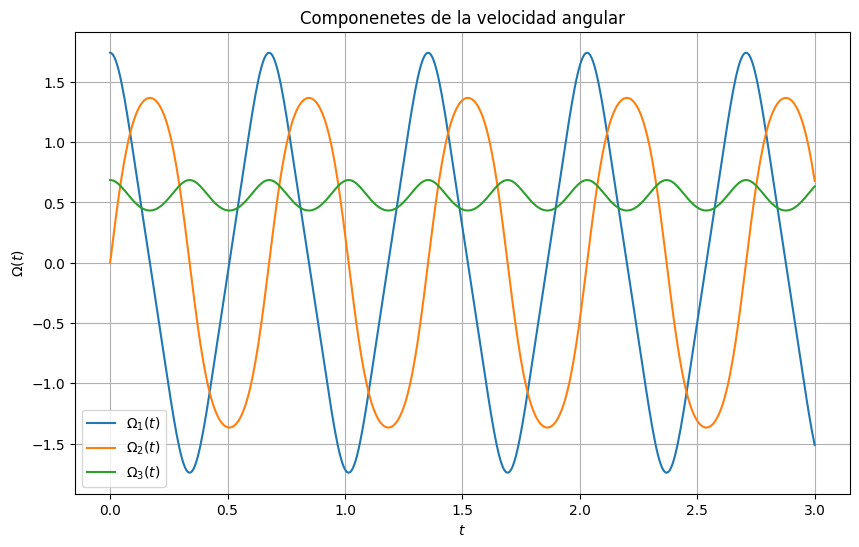

In [4]:
# Graficar de las soluciones analíticas para las componentes de la velocidad angular.

plt.figure(figsize=(10, 6))
plt.plot(t, Ω1, label='$Ω_1 (t)$')
plt.plot(t, Ω2, label='$Ω_2 (t)$')
plt.plot(t, Ω3, label='$Ω_3 (t)$')
plt.xlabel('$t$')
plt.title('Componenetes de la velocidad angular')
plt.ylabel('$Ω(t)$')
plt.legend()
plt.grid()
plt.show()



In [5]:
from matplotlib.animation import FuncAnimation
from IPython import display

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Lista para almacenar la trayectoria
trajectory = []

start = np.array([0, 0, 0])
# Función de actualización para la animación
def update(frame):
    ax.cla()  # Limpiar el gráfico

    # Configurar los límites del gráfico
    ax.set_xlim([-3, 3])
    ax.set_ylim([-2, 2])
    ax.set_zlim([0, 6])

    # Etiquetas de los ejes
    ax.set_xlabel(r'x')
    ax.set_ylabel(r'y')
    ax.set_zlabel(r'z')

    # Título del gráfico
    ax.set_title('Trayectoria de $\Omega$')

    # Dibujar la nueva flecha (quiver)
    quiver = ax.quiver(start[0], start[1], start[2], Ω1[frame], Ω2[frame], Ω3[frame],color='k',arrow_length_ratio=0.05)

    # Agregar el punto actual a la trayectoria
    trajectory.append((Ω1[frame], Ω2[frame], Ω3[frame]))

    # Dibujar la trayectoria como puntos
    trajectory_array = np.array(trajectory)
    ax.scatter(trajectory_array[:, 0], trajectory_array[:, 1], trajectory_array[:, 2], marker='o')

    return quiver,

# Crear la animación
ani = FuncAnimation(fig, update, frames=len(Ω1), blit=False, interval=100, repeat=False)
#plt.show()

#ani

video=ani.to_html5_video()
html=display.HTML(video)
display.display(html)
plt.close()


Las funciones elípticas de Jacobi  son periódicas, por tanto comprenden un período de 4K con respecto a la variación de $\tau$, dada K como la integral elíptica de primera especie:

$$
K = \int_{0}^{1} \frac{ds}{\sqrt{(1-s^2)(1-k^2s^2)}} = \int_{0}^{\pi/2} \frac{du}{\sqrt{(1-k^2sen^2u)}} \tag{14}
$$

Por tanto el período respecto a t, viene dado como

$$
T = 4K\sqrt{\frac{I_1I_2I_3}{(I_3-I_2)(M^2-2EI_1)}} \tag{15}
$$

Numericamente se obtine lo siguiente:

In [26]:
from scipy.special import ellipkinc

# Parámetros
phi = np.pi / 2  # ángulo en radianes
k=np.sqrt(((I2-I1)*(2*E*I3 - M**2))/((I3-I2)*(M**2 -2*E*I1))) # parámetro modular

# Integral elíptica de primera clase
K = ellipkinc(phi, k)
T = 4*K*np.sqrt((I1*I2*I3)/((I3-I2)*(M**2-2*E*I1)))
print("K = ", K)
print("T = ", T)

K =  1.950730145707912
T =  4.061776128360967


Una vez se conoce el movimiento en el sistema del cuerpo, veamos el movimiento en el sistema de referencia inercial.
Dada la rotación del cuerpo alrededor de sus ejes, es conveniente determinar el movimiento absoluto de la peonza en el espacio en función del tiempo, es decir, respecto al sistema fijo de coordenadas $X,Y,Z$. Para lograrlo, se usan los agulos de Euler $\psi, \phi, \theta$ entre los ejes del cuerpo $x_1, x_2, x_3 $ y los ejes $X, Y, Z$. Tomando el eje Z en la dirección del vector constante M. Se puede escribir:

$$
\begin{cases} M_1 = I_1\Omega_1 = Msen\theta sen\psi \\ M_2 = I_2\Omega_2 = Msen\theta cos\psi \\M_3 = I_3\Omega_3 = Mcos\theta \end{cases} \tag{16}
$$

de donde
$$
\begin{cases} cos\theta = \frac{I_3\Omega_3}{M} \\ tan\psi = \frac{I_1\Omega_1}{I_2\Omega_2} \end{cases} \tag{17}
$$

Para hallar la expresión asociada a $\phi$, se recurre a las relacioines entre los ángulos de Euler y las componenetes de la velocidad angular:

$$\Omega_1 =\dot{\phi} \sin(\theta) \sin(\psi) + \dot{\theta} \cos(\psi)$$
$$\Omega_2 =\dot{\phi} \sin(\theta) \cos(\psi) - \dot{\theta} \sin(\psi)$$

Obteniendo:
$$\dot{\phi}=\frac{\Omega_1 \sin(\psi)+\Omega_2 \cos(\psi)}{\sin(\theta)}$$


Usando las relaciones entre las componentes de la velocidad angular y del momento angular, se tiene que:


De modo que, reemplazando $(13)$, se llega a

$$
\begin{cases}cos\theta = \sqrt{\frac{I_3(M^2-2EI_1)}{M^2(I_3-I_1)}} dn\tau \\ tan\psi = \sqrt{\frac{I_1(I_3-I_2)}{I_2(I_3-I_1)}} \frac{cn\tau}{sn\tau} \\
\dot{\phi}=\frac{M (I_1{\Omega_1}^2+I_2{\Omega_2}^2)}{{I_1}^2{\Omega_1}^2+{I_2}^2{\Omega_2}^2} \end{cases} \tag{18}
$$

lo cual determina $\theta$, $\psi$ y $\phi$ en función del tiempo. Numericamente se tiene lo siguiente

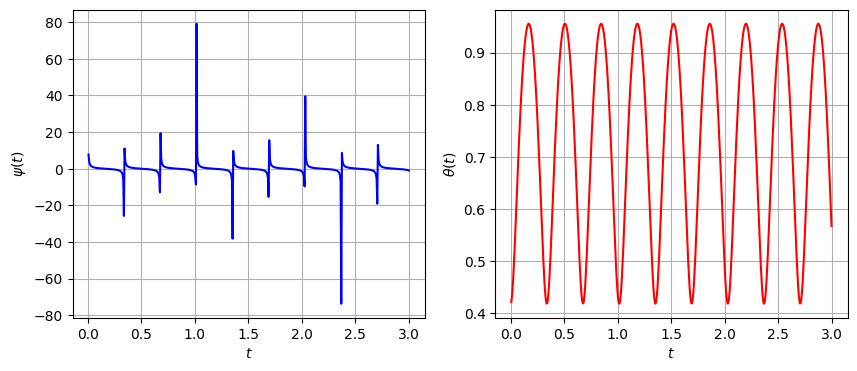

In [8]:

θ=np.arccos( np.sqrt((I3*(M**2 - 2*E*I1))/(M**2 *(I3-I1))) * dn )
ψ=np.arctan( np.sqrt((I1*(I3-I2))/(I2*(I3-I1))) )* (cn[1::]/sn[1::])


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(t[1::],ψ,color='blue')
plt.xlabel('$t$')
plt.ylabel('$ψ(t)$')
plt.grid()

plt.subplot(1,2,2)
plt.plot(t[1::],θ[1::],color='red')
plt.xlabel('$t$')
plt.ylabel('$θ(t)$')
plt.grid()

### Referencias:

*   Landau, L. (1994). Mecánica.Reverté
*   https://galileo-unbound.blog/tag/intermediate-axis-theorem/

